# 04 Task 4: water freshness
**Problem.** Water age is taken as proportional to the shortest-path distance it travels from its source. For each sector $V_s$ (task 3) find
$$t_s=\arg\max_{v\in V_s} d_G(s,v),$$
its distance $d_G(s,t_s)$ and the route that realises it, and compare distances before and after sectorization.

**Input:** the instance, pipe lengths (task 2) and the sectors with their multi-source Dijkstra distances and parent pointers (task 3). **Output:** per sector, the farthest node, its distance and its route.

**How the sectors were obtained.** Exactly as in task 3: multi-source Dijkstra over pipe lengths assigns each node to its closest source, and the pipes between sectors are closed. `water.tasks.sectorize` is called here so the sectors are identical to task 3's.

**Technique: greedy shortest paths (Dijkstra) plus shortest-path tree reconstruction.** Dijkstra already leaves a parent pointer for every node, forming a shortest-path tree rooted at the sources; the farthest node is an $O(V)$ scan of the distances and its route is read by following parents back to the source.

In [1]:
import os, sys
if 'google.colab' in sys.modules and not os.path.isdir('../water'):
    os.system('git clone -q https://github.com/santihdzs/water-distribution')
    os.chdir('water-distribution/notebooks')
sys.path.insert(0, os.path.abspath('..'))

import inspect
import matplotlib.pyplot as plt
import networkx as nx
import water
from water import graph, paths, plot, tasks

plot.setup()
nets = water.load_all()
secs = {name: tasks.sectorize(net) for name, net in nets.items()}
fars = {name: tasks.farthest(net, secs[name]) for name, net in nets.items()}

In [2]:
print(inspect.getsource(tasks.farthest))
print(inspect.getsource(paths.path_to))

def farthest(net, sec):
    """t4: per sector, the node with the largest shortest-path distance from its source."""
    out = {}
    for s, nodes in sec['members'].items():
        t = max(nodes, key=lambda u: (sec['dist'][u], -u))
        out[s] = {'node': t, 'dist': sec['dist'][t], 'route': path_to(sec['parent'], t)}
    return out

def path_to(parent, t):
    route = []
    while t is not None:
        route.append(t)
        t = parent[t]
    return route[::-1]



## Correctness
For each sector: the route starts at the source, ends at the farthest node, uses only pipes that exist and stay open, and its length equals the reported distance. As an independent baseline, networkx Dijkstra is run on the closed sector subgraph and must find the same farthest distance.

In [3]:
for name, net in nets.items():
    sec, far = secs[name], fars[name]
    open_pipes = {frozenset(p[:2]) for p in sec['kept']}
    for s, f in far.items():
        r = f['route']
        assert r[0] == s and r[-1] == f['node']
        assert all(frozenset(e) in open_pipes for e in zip(r, r[1:]))
        assert abs(sum(net.length(a, b) for a, b in zip(r, r[1:])) - f['dist']) < 1e-9
        H = nx.Graph()
        H.add_weighted_edges_from((u, v, net.length(u, v)) for u, v, _ in sec['kept'] if sec['origin'][u] == s)
        ref = nx.single_source_dijkstra_path_length(H, s)
        assert abs(max(ref.values()) - f['dist']) < 1e-9 and set(ref) == set(sec['members'][s])
print('routes valid, distances match networkx on every closed sector')

routes valid, distances match networkx on every closed sector


## Before and after sectorization
Two comparisons.

- **Per node.** Task 3 already showed that closing the boundary pipes leaves every node's distance to its own source unchanged, so for the nodes a source keeps, water is exactly as fresh after sectorization as before.
- **Per source.** Before sectorization a single source could be asked to reach the whole network; its farthest node is then its eccentricity in the open network (one Dijkstra from $s$ on all pipes). After sectorization it only serves its sector. The ratio shows how much sectorization shortens the worst water age each source is responsible for.

In [4]:
rows = []
for name, net in nets.items():
    adj = graph.adjacency_list(net)
    for s, f in fars[name].items():
        d, parent, _ = paths.dijkstra(adj, s)
        before = max(d, key=lambda u: (d[u], -u))
        hops = len(f['route']) - 1
        print(f'{name} source {s}: farthest in sector = node {f["node"]} at {f["dist"]:.2f} via {hops} pipes '
              f'{"-".join(map(str, f["route"]))}')
        print(f'      whole network before sectorization: node {before} at {d[before]:.2f} '
              f'({d[before] / f["dist"]:.2f}x the sector value)')
        rows.append([name, s, f['node'], f['dist'], hops, before, d[before], d[before] / f['dist']])

plot.table('farroutes', [[name, s, f['node'], '-'.join(map(str, f['route']))] for name in nets for s, f in fars[name].items()],
           ['Inst.', '$s$', '$t_s$', 'Route'], ['{}', '{}', '{}', '{}'])
plot.table('freshness', rows,
           ['Inst.', 'Source', 'Farthest', r'$d_G(s,t_s)$', 'Pipes', 'Farthest before', r'$d_G$ before', 'Ratio'],
           ['{}', '{}', '{}', '{:,.1f}', '{}', '{}', '{:,.1f}', '{:.2f}'])

NYT source 17: farthest in sector = node 3 at 1883.33 via 8 pipes 17-10-9-8-7-6-5-4-3
      whole network before sectorization: node 1 at 2335.26 (1.24x the sector value)
NYT source 19: farthest in sector = node 2 at 2101.17 via 7 pipes 19-18-12-13-14-15-1-2
      whole network before sectorization: node 3 at 2331.40 (1.11x the sector value)
HAN source 13: farthest in sector = node 8 at 4963.12 via 5 pipes 13-12-11-10-9-8
      whole network before sectorization: node 29 at 13638.04 (2.75x the sector value)
HAN source 1: farthest in sector = node 31 at 9531.23 via 11 pipes 1-2-3-19-18-17-16-27-26-25-32-31
      whole network before sectorization: node 31 at 9531.23 (1.00x the sector value)
FOS source 7: farthest in sector = node 12 at 4931.09 via 5 pipes 7-6-21-14-13-12
      whole network before sectorization: node 37 at 7370.56 (1.49x the sector value)
FOS source 37: farthest in sector = node 3 at 4131.72 via 4 pipes 37-1-17-2-3
      whole network before sectorization: node 6 at 752

## Figure

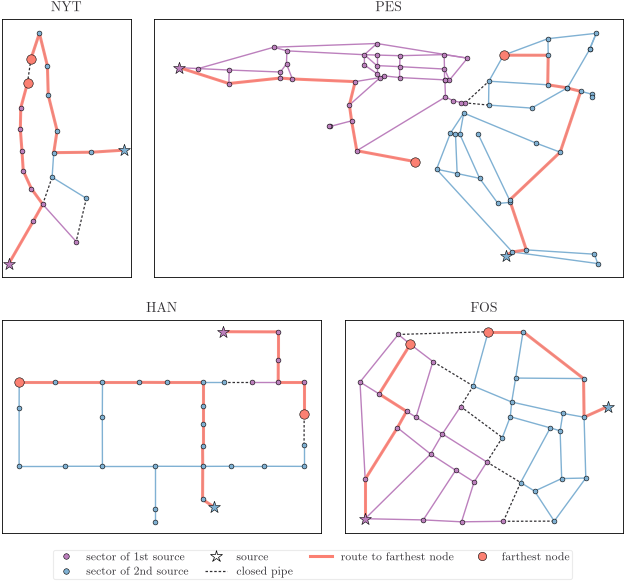

In [5]:
fig, axes = plot.instance_axes(nets)
for name, ax in axes.items():
    net = nets[name]
    plot.sector_map(ax, net, secs[name])
    for s, f in fars[name].items():
        plot.route(ax, net, f['route'], lw=2.2, zorder=2, alpha=0.9)
        plot.nodes(ax, net, [f['node']], color=plot.HIGHLIGHT, s=46, marker='o', zorder=6)
    plot.frame(ax, name)
extra = [plt.Line2D([], [], color=plot.HIGHLIGHT, lw=2.2, label='route to farthest node'),
         plt.Line2D([], [], ls='', marker='o', mfc=plot.HIGHLIGHT, mec='k', mew=0.4, ms=6, label='farthest node')]
plot.sector_legend(fig, extra)
plot.save(fig, 'freshness')
plt.show()

## Complexity
On top of the task 3 Dijkstra ($O((V+E)\log V)$), finding each farthest node is $O(V)$ and reconstructing its route is $O(V)$; memory is the $O(V)$ distance and parent maps. The before-sectorization comparison adds one Dijkstra per source, $O(|S|(V+E)\log V)$.

## Interpretation
The farthest node of each sector is where water is oldest, so it is the natural place to monitor residual disinfectant or to flush. Four of the eight (NYT 3 and 2, HAN 8, FOS 3) sit at a closed pipe, where the two sources' supply areas meet; the others lie at the far extremity of their sector (PES 10 is a leaf, HAN 31 the west corner). Sectorization cuts the worst water age each source is responsible for by a factor of 1.49 to 2.25 in FOS and PES and matters most for HAN source 13, which alone would have to reach node 29 at 13,638 units, 2.75 times its sector's worst case. HAN source 1 is the exception (ratio 1.00): its farthest node is the same with or without the other source. The farthest node of each sector is also the sink of the task 5 maximum-flow problem.